<a href="https://colab.research.google.com/github/AhmadSyahreza/Data-Analyst/blob/main/HW_AhmadSyahreza_Stat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Import library dan membaca data

- `pandas` untuk baca dan memeriksa data.
- `matplotlib` dan `seaborn` untuk visualisasi.
- `scipy.stats` untuk uji hipotesis (Dari ketentuan tugas).

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from google.colab import files
uploaded = files.upload()
#Disini isi/pilih berdasarkan file yang kita mau
#Nama file dri tugasnya : 16f605836be46a2a7a25487f9d8b6d38.csv
csv_path = next(iter(uploaded))
df = pd.read_csv(csv_path)

print("Ukuran data :", df.shape)
display(df.head())

Saving 16f605836be46a2a7a25487f9d8b6d38.csv to 16f605836be46a2a7a25487f9d8b6d38 (1).csv
Ukuran data : (200, 10)


,custid,sex,AqChannel,region,Marital_status,segment,pre_usage,Post_usage_1month,Latest_mon_usage,post_usage_2ndmonth
0,70,0,4,1,1,1,57,52,49.2,57.2
1,121,1,4,2,1,3,68,59,63.6,64.9
2,86,0,4,3,1,1,44,33,64.8,36.3
3,141,0,4,3,1,3,63,44,56.4,48.4
4,172,0,4,2,1,2,47,52,68.4,57.2


KALAU YANG DIATAS GABISA DIAKSES PAKAI YG DI DRIVE INI AJA YA MAS/MBA. KARENA INI PAKAI DRIVENYA SAYAA


---

Nanti si kodenya tinggal bacaa drive sayaa

In [22]:
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/DigitalSkola'
df = pd.read_csv(f'{BASE}/16f605836be46a2a7a25487f9d8b6d38.csv')

print("Ukuran data :", df.shape)
display(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1a. Periksa `info()` dan `describe()`

`info()` menampilkan jumlah data terisi dan tipe data tiap kolom. `describe()` merangkum statistik numerik, seperti rata-rata, standar deviasi, kuartil, nilai minimum, dan maksimum.

df disini berdasarkaan cell yg di paling atas alias isi dari `16f605836be46a2a7a25487f9d8b6d38.csv`

In [14]:
df.info()
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   custid               200 non-null    int64  
 1   sex                  200 non-null    int64  
 2   AqChannel            200 non-null    int64  
 3   region               200 non-null    int64  
 4   Marital_status       200 non-null    int64  
 5   segment              200 non-null    int64  
 6   pre_usage            200 non-null    int64  
 7   Post_usage_1month    200 non-null    int64  
 8   Latest_mon_usage     200 non-null    float64
 9   post_usage_2ndmonth  200 non-null    float64
dtypes: float64(2), int64(8)
memory usage: 15.8 KB


,custid,sex,AqChannel,region,Marital_status,segment,pre_usage,Post_usage_1month,Latest_mon_usage,post_usage_2ndmonth
count,200.000000,200.00000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,0.54500,3.430000,2.055000,1.160000,2.025000,52.230000,52.775000,63.174000,58.052500
std,57.879185,0.49922,1.039472,0.724291,0.367526,0.690477,10.252937,9.478586,11.242137,10.426445
min,1.000000,0.00000,1.000000,1.000000,1.000000,1.000000,28.000000,31.000000,39.600000,34.100000
25%,50.750000,0.00000,3.000000,2.000000,1.000000,2.000000,44.000000,45.750000,54.000000,50.325000
50%,100.500000,1.00000,4.000000,2.000000,1.000000,2.000000,50.000000,54.000000,62.400000,59.400000
75%,150.250000,1.00000,4.000000,3.000000,1.000000,2.250000,60.000000,60.000000,70.800000,66.000000
max,200.000000,1.00000,4.000000,3.000000,2.000000,3.000000,76.000000,67.000000,90.000000,73.700000


### Pemeriksaan data hilang dan jumlah pelanggan per jenis kelamin

kewajiban dalam suatu data science dan yang sudah dilakukan di tugas sebelumnya ialah kita harus ngecek data yang hilang

Menurut keterangan dataset, `sex = 0` adalah laki-laki dan `sex = 1` adalah perempuan. ini akan kita gunakan untuk mengklasifikasiin si data

In [15]:
print("nilai kosong setiap kolom :")
display(df.isna().sum())

print("pelanggan per kelamin:")
display(df["sex"].map({0: "Laki-laki", 1: "Perempuan"}).value_counts())

nilai kosong setiap kolom :


,0
custid,0
sex,0
AqChannel,0
region,0
Marital_status,0
segment,0
pre_usage,0
Post_usage_1month,0
Latest_mon_usage,0
post_usage_2ndmonth,0


pelanggan per kelamin:


,count
sex,
Perempuan,109
Laki-laki,91


## 1b. Histogram variabel penting

Histogram dipakai untuk melihat bentuk persebaran nilai penggunaan kartu kredit sebelum kampanye, satu bulan setelah kampanye, dan dua bulan setelah kampanye.

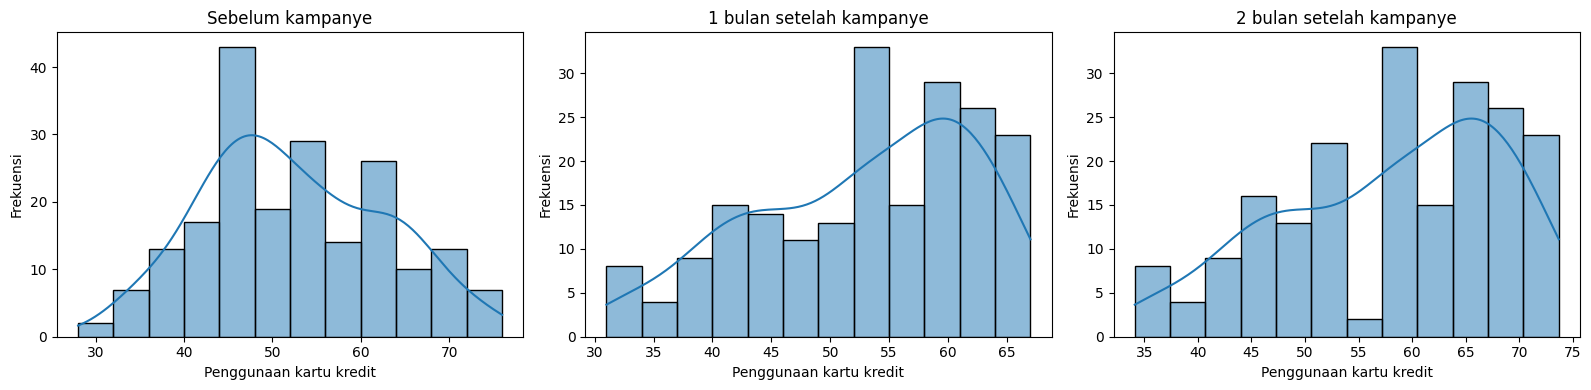

In [16]:
usage_cols = ["pre_usage", "Post_usage_1month", "post_usage_2ndmonth"] #dari data aku ngeliat ada 3 pembagian gitu
usage_labels = {
    "pre_usage": "Sebelum kampanye", #Sesuai arti yang di datanya itu artinya sebelum
    "Post_usage_1month": "1 bulan setelah kampanye", #Post yang berarti setelah dan 1month artinya 1 bulan
    "post_usage_2ndmonth": "2 bulan setelah kampanye" #Post yang berarti setelah dan 1month artinya 2 bulan
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, usage_cols):
    sns.histplot(data=df, x=col, bins=12, kde=True, ax=ax)
    ax.set_title(usage_labels[col])
    ax.set_xlabel("Penggunaan kartu kredit") #Banyak penggunaannya
    ax.set_ylabel("Frekuensi") #Banyak Penggunanya
plt.tight_layout()
plt.show()

### Perbandingan rata-rata penggunaan

Grafik rata-rata membantu melihat perubahan nilai tengah penggunaan pada tiga waktu pengamatan.
---
Tiga waktu disini tuh ada `pre`, `post 1 month`,dan `post 2 month`

,Rata-rata penggunaan
Sebelum kampanye,52.2300
1 bulan setelah kampanye,52.7750
2 bulan setelah kampanye,58.0525


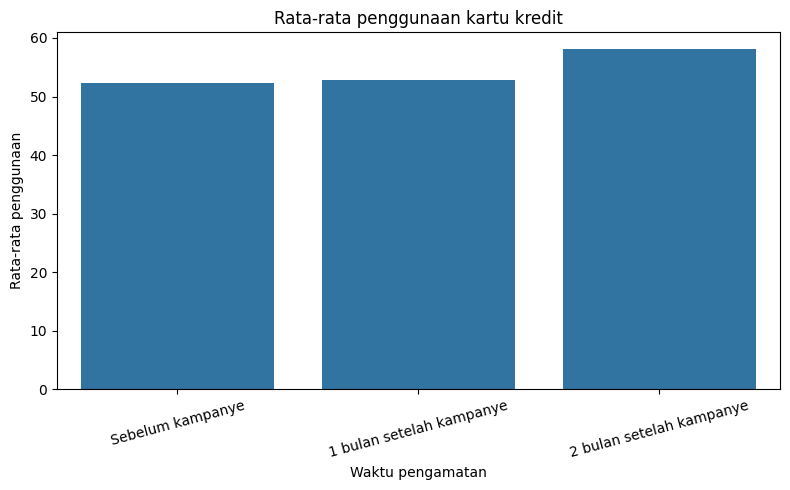

In [17]:
mean_usage = df[usage_cols].mean().rename(index=usage_labels)
display(mean_usage.rename("Rata-rata penggunaan").to_frame())

plt.figure(figsize=(8, 5))
sns.barplot(x=mean_usage.index, y=mean_usage.values)
plt.title("Rata-rata penggunaan kartu kredit")
plt.xlabel("Waktu pengamatan")
plt.ylabel("Rata-rata penggunaan")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 2. Uji hipotesis sebelum vs setelah kampanye

degan menggunakan **paired t-test** (`scipy.stats.ttest_rel`) karena nilai sebelum dan setelah kampanye berasal dari pelanggan yang sama.

Taraf signifikansi: **α = 0,05**. Pengujian dua arah

- **H₀:** rata-rata penggunaan sebelum kampanye sama dengan rata-rata penggunaan setelah kampanye (rata-rata selisih = 0).
- **H₁:** rata-rata penggunaan sebelum kampanye berbeda dengan rata-rata penggunaan setelah kampanye (rata-rata selisih ≠ 0).

In [18]:
alpha = 0.05 #Deklaerasiin nilai alpha nya

def paired_test(before_col, after_col, after_label): #bikin method berdasarkan sebelum dan sesudah
    #deklarasiin datanya yg mana di setiap bagian `before` dan `After`
    before = df[before_col]
    after = df[after_col]


    paired = df[[before_col, after_col]].dropna()
    result = stats.ttest_rel(paired[before_col], paired[after_col])

    #Nilai rata rata berdasaarkan inputan pada `method paired_test`
    mean_before = paired[before_col].mean()
    mean_after = paired[after_col].mean()
    mean_change = (paired[after_col] - paired[before_col]).mean()

    print(f"Perbandingan: sebelum kampanye vs {after_label}")
    print(f"n pasangan = {len(paired)}")
    print(f"Rerata sebelum = {mean_before:.3f}")
    print(f"Rerata setelah = {mean_after:.3f}")
    print(f"Rerata perubahan (setelah - sebelum) = {mean_change:.3f}")
    print(f"t-statistic = {result.statistic:.4f}")
    print(f"p-value = {result.pvalue:.8g}")
    if result.pvalue < alpha:
        print("Tolak H0.") #ini merupakan bagian dari rumus statistika yg menggunakan h0 dan h1
        print("terdapat perbedaan rata-rata yang signifikan secara statistik.")
    else:
        print("Gagal menolak H0.")
        print("bukti belum cukup untuk menyatakan adanya perbedaan rata-rata yang signifikan.")
    print("-" * 60)
    return result

test_1month = paired_test("pre_usage", "Post_usage_1month", "1 bulan setelah") #pada 1 bulan setelah
test_2month = paired_test("pre_usage", "post_usage_2ndmonth", "2 bulan setelah") #2 bulan setelah

Perbandingan: sebelum kampanye vs 1 bulan setelah
n pasangan = 200
Rerata sebelum = 52.230
Rerata setelah = 52.775
Rerata perubahan (setelah - sebelum) = 0.545
t-statistic = -0.8673
p-value = 0.38681868
Gagal menolak H0.
bukti belum cukup untuk menyatakan adanya perbedaan rata-rata yang signifikan.
------------------------------------------------------------
Perbandingan: sebelum kampanye vs 2 bulan setelah
n pasangan = 200
Rerata sebelum = 52.230
Rerata setelah = 58.053
Rerata perubahan (setelah - sebelum) = 5.823
t-statistic = -8.8668
p-value = 4.2957338e-16
Tolak H0.
terdapat perbedaan rata-rata yang signifikan secara statistik.
------------------------------------------------------------


### Baca hasil penggunaan statistika No. 2

Bandingkan `p-value` dengan 0,05:
- Jika `p-value < 0,05`, **tolak H₀**: perbedaan rata-rata signifikan.
- Jika `p-value ≥ 0,05`, **gagal menolak H₀**: bukti belum cukup untuk menyatakan perbedaan signifikan.

Rata-rata perubahan dihitung sebagai `setelah − sebelum`


---


nilai positif berarti rata-rata penggunaan lebih tinggi setelah kampanye. Signifikansi statistik tidak otomatis membuktikan bahwa kampanye adalah satu-satunya penyebab perubahan.

## 3. Uji hipotesis independen untuk laki-laki vs perempuan setelah kampanye

Menggunakan **independent-samples t-test** (`scipy.stats.ttest_ind`) untuk membandingkan dua kelompok pelanggan yang berbeda.

Untuk masing-masing waktu (1 bulan dan 2 bulan):
- **H₀:** rata-rata penggunaan laki-laki sama dengan rata-rata penggunaan perempuan.
- **H₁:** rata-rata penggunaan laki-laki berbeda dari rata-rata penggunaan perempuan.

Taraf signifikansi **α = 0,05**, dua arah. Kode di bawah memakai versi Welch (`equal_var=False`) yang tidak mensyaratkan varians kedua kelompok sama. Asumsi utamanya: kelompok independen, data numerik, dan distribusi dalam tiap kelompok tidak terlalu menyimpang dari normalitas atau didominasi pencilan ekstrem.

In [19]:
def gender_test(usage_col, period_label):
    male = df.loc[df["sex"] == 0, usage_col].dropna()
    female = df.loc[df["sex"] == 1, usage_col].dropna()
    result = stats.ttest_ind(male, female, equal_var=False)

    print(f"Perbandingan jenis kelamin: {period_label}")
    print(f"Laki-laki: n = {len(male)}, rata-rata = {male.mean():.3f}, SD = {male.std(ddof=1):.3f}")
    print(f"Perempuan: n = {len(female)}, rata-rata = {female.mean():.3f}, SD = {female.std(ddof=1):.3f}")
    print(f"Selisih rata-rata (laki-laki - perempuan) = {male.mean() - female.mean():.3f}")
    print(f"t-statistic = {result.statistic:.4f}")
    print(f"p-value = {result.pvalue:.8g}")
    if result.pvalue < alpha:
        print("Keputusan: Tolak H0.")
        print("Kesimpulan: rata-rata penggunaan laki-laki dan perempuan berbeda signifikan.")
    else:
        print("Keputusan: Gagal menolak H0.")
        print("Kesimpulan: belum ada bukti perbedaan rata-rata yang signifikan.")
    print("-" * 60)
    return result

gender_1month = gender_test("Post_usage_1month", "1 bulan setelah kampanye")
gender_2month = gender_test("post_usage_2ndmonth", "2 bulan setelah kampanye")

Perbandingan jenis kelamin: 1 bulan setelah kampanye
Laki-laki: n = 91, rata-rata = 50.121, SD = 10.305
Perempuan: n = 109, rata-rata = 54.991, SD = 8.134
Selisih rata-rata (laki-laki - perempuan) = -4.870
t-statistic = -3.6564
p-value = 0.00034088494
Keputusan: Tolak H0.
Kesimpulan: rata-rata penggunaan laki-laki dan perempuan berbeda signifikan.
------------------------------------------------------------
Perbandingan jenis kelamin: 2 bulan setelah kampanye
Laki-laki: n = 91, rata-rata = 55.133, SD = 11.336
Perempuan: n = 109, rata-rata = 60.490, SD = 8.947
Selisih rata-rata (laki-laki - perempuan) = -5.357
t-statistic = -3.6564
p-value = 0.00034088494
Keputusan: Tolak H0.
Kesimpulan: rata-rata penggunaan laki-laki dan perempuan berbeda signifikan.
------------------------------------------------------------


### Visualisasi penggunaan setelah kampanye menurut jenis kelamin

Boxplot berfungsi untuk membandingkan median, rentang antarkuartil, persebaran, dan kemungkinan pencilan pada kedua kelompok.

Namun, boxplot bukan pengganti uji hipotesis.

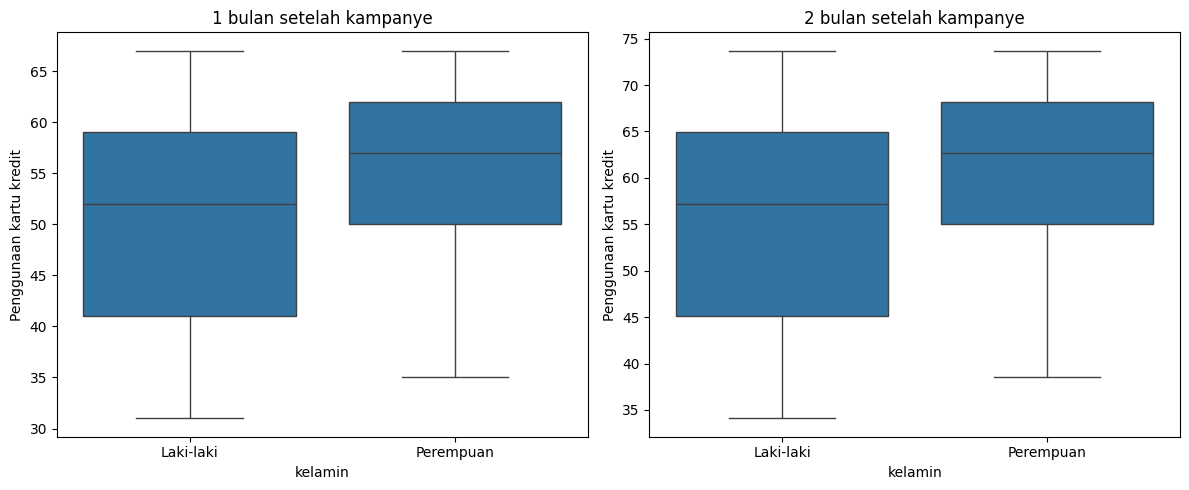

In [20]:
df_plot = df.copy()
df_plot["kelamin"] = df_plot["sex"].map({0: "Laki-laki", 1: "Perempuan"})

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=df_plot, x="kelamin", y="Post_usage_1month", ax=axes[0])
axes[0].set_title("1 bulan setelah kampanye")
axes[0].set_xlabel("kelamin")
axes[0].set_ylabel("Penggunaan kartu kredit")

sns.boxplot(data=df_plot, x="kelamin", y="post_usage_2ndmonth", ax=axes[1])
axes[1].set_title("2 bulan setelah kampanye")
axes[1].set_xlabel("kelamin")
axes[1].set_ylabel("Penggunaan kartu kredit")

plt.tight_layout()
plt.show()

## 4. kesimpulan

Gunakan keluaran dari sel uji hipotesis untuk menuliskan keputusan berdasarkan p-value. Pada data ini, ringkasan hasil yang diharapkan adalah:

1. **Sebelum vs 1 bulan setelah kampanye:** rata-rata naik sedikit, tetapi perbedaannya tidak signifikan pada α = 0,05.
2. **Sebelum vs 2 bulan setelah kampanye:** rata-rata lebih tinggi dan perbedaannya signifikan pada α = 0,05.
3. **Laki-laki vs perempuan, 1 bulan setelah kampanye:** terdapat perbedaan rata-rata yang signifikan; rata-rata kelompok perempuan lebih tinggi.
4. **Laki-laki vs perempuan, 2 bulan setelah kampanye:** terdapat perbedaan rata-rata yang signifikan; rata-rata kelompok perempuan lebih tinggi.



---



**Batasan interpretasi:** hasil ini menunjukkan perubahan/perbedaan statistik pada data yang dianalisis, bukan bukti kausal yang pasti bahwa kampanye sendirian menyebabkan perubahan.


---


Analisis juga menganggap setiap baris mewakili satu pelanggan dan pengukuran yang dibandingkan menggunakan definisi penggunaan yang konsisten.